In [13]:
#Requirements

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from scipy.ndimage import median_filter, uniform_filter1d
from scipy.signal import savgol_filter, butter, sosfiltfilt, detrend

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import  StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error



#"Random common shapes with noise - data generation"

rng = np.random.default_rng(42)


def generate_clean_signal(variant, length_per_section=100):

    n = length_per_section
    offset = rng.uniform(-0.5, 0.5)

    # Flat signal
    flat = np.full(n, 10 + offset)

    # Trend signal
    x = np.arange(n)
    trend = 10 + offset + 0.04 * x

    # Peak
    center = n / 2 + rng.uniform(-8, 8)
    width = rng.uniform(12, 18)
    peak = (
        14 + offset
        + 4 * np.exp(-0.5 * ((x - center) / width) ** 2)
    )

    # Change in the signal level - Step
    step = np.full(n, 14 + offset)
    step[n // 2:] = 18 + offset

    # Flat signal but at a different level
    flat_new = np.full(n, 18 + offset)

    return np.concatenate([flat, trend, peak, step, flat_new])

#Lets add noise to the clean signal of 3 different types:
def add_noise(clean_signal, noise_type, strength):

    if noise_type == "random":
        noise = rng.normal(0, strength, len(clean_signal))

    elif noise_type == "spikes":
        noise = rng.normal(0, 0.15 * strength, len(clean_signal))

        spike_count = max(1, int(len(clean_signal) * 0.04))
        positions = rng.choice(
            len(clean_signal), size=spike_count, replace=False
        )
        noise[positions] += rng.choice(
            [-1, 1], size=spike_count
        ) * 4 * strength

    elif noise_type == "drift":
        # Gradual change in the noise level across the signal.
        drift = np.linspace(
            -2 * strength, 2 * strength, len(clean_signal)
        )
        noise = drift + rng.normal(
            0, 0.15 * strength, len(clean_signal)
        )

    else:
        raise ValueError("Unknown noise type")

    return clean_signal + noise


# 2. Generate full mixed-signal variants with noise

generated_signals = []

noise_types = ["random", "spikes", "drift"]
noise_strengths = [0.3, 0.7, 1.2]

for variant in range(12):

    # Generate one full signal containing all five sections
    clean_signal = generate_clean_signal(variant)

    # Create noisy versions of this signal
    for noise_type in noise_types:
        for strength in noise_strengths:

            noisy_signal = add_noise(
                clean_signal,
                noise_type,
                strength
            )

            # Store everything needed for windowing and filter testing
            generated_signals.append({
                "variant": variant,
                "noise_type": noise_type,
                "noise_strength": strength,
                "clean_signal": clean_signal.copy(),
                "noisy_signal": noisy_signal
            })

print("Total noisy signals:", len(generated_signals))




Total noisy signals: 108


In [14]:
#Sliding window features
#the window configuration is adjsutable by changing the window size and overlapping step size!
WINDOW_SIZE = 100
STEP_SIZE = 35


def get_window_starts(signal_length):


    starts = list(
        range(0, signal_length - WINDOW_SIZE + 1, STEP_SIZE)
    )

    #last window must be included if otherwise does not fulfill the selection range criteria!!
    final_start = signal_length - WINDOW_SIZE
    if starts[-1] != final_start:
        starts.append(final_start)

    return starts

In [15]:
# Creating Filters with their different settings to be applied

Filter_Config = []

#Median Filter
for size in [5,10,15]:
  Filter_Config.append({
      "name": "Median Filter",
      "filter_window": size,
      "polyorder": np.nan,
      "cutoff": np.nan,
      "filter_order": np.nan })

#Moving Average Filter
for size in [5,10,15]:
  Filter_Config.append({
      "name": "Moving Average",
      "filter_window": size,
      "polyorder": np.nan,
      "cutoff": np.nan,
      "filter_order": np.nan })

#Sav_gol Filter
for size in [5,10,15]:
  for order in [2,3]:
    Filter_Config.append({
        "name": "Savitzky-Golay",
        "filter_window": size,
        "polyorder": order,
        "cutoff": np.nan,
        "filter_order": np.nan })

#Butterworth Filter

for cutoff in [0.05, 0.1, 0.2]:
  for order in [2,3]:
    Filter_Config.append({
        "name": "Butterworth",
        "filter_window": np.nan,
        "polyorder": np.nan,
        "cutoff": cutoff,
        "filter_order": order })

#linear detrending Filter

Filter_Config.append({
    "name": "Linear Detrending",
    "filter_window": np.nan,
    "polyorder": np.nan,
    "cutoff": np.nan,
    "filter_order": np.nan })

In [16]:
#Lets apply the filters in a loop with different settings and defined configurations!


def apply_filters(signal, filter_config):

  name = filter_config ["name"]

  if name == "Median Filter":
    return median_filter (signal, size= int(filter_config["filter_window"]))

  elif name == "Moving Average":
    return uniform_filter1d(signal,size = int(filter_config["filter_window"]))

  elif name == "Savitzky-Golay":
    return savgol_filter(signal, window_length=int(filter_config["filter_window"]), polyorder=int(filter_config["polyorder"]))

  elif name == "Butterworth":
    sos = butter(int(filter_config["filter_order"]), filter_config["cutoff"], btype='low', output='sos')
    return sosfiltfilt (sos, signal)

  elif name == "Linear Detrending":
    return detrend(signal)

  else:
    raise ValueError("Unknown filter name")

In [17]:

# Apply every filter to every window and record performance

results = []

for signal_data in generated_signals:

    clean_signal = signal_data["clean_signal"]
    noisy_signal = signal_data["noisy_signal"]


    window_starts = get_window_starts(len(noisy_signal))

    for start in window_starts:

        end = start + WINDOW_SIZE

        noisy_window = noisy_signal[start:end]
        clean_window = clean_signal[start:end]


        for filter_config in Filter_Config: #which is defined earlier

            filtered_window = apply_filters(
                noisy_window, filter_config
            )


            errors = filtered_window - clean_window

            rmse = np.sqrt(np.mean(errors ** 2))
            mae = np.mean(np.abs(errors))

            #### NEW: Calculate SNR in decibels, following the paper's approach.
            #### Compare the clean window with the filtered window.
            signal_power = np.sum(clean_window ** 2)
            error_power = np.sum(errors ** 2)

            if error_power > 0:
                snr = 10 * np.log10(signal_power / error_power)
            else:
                snr = np.inf  # Perfect reconstruction: no remaining error.


            results.append({
                "variant": signal_data["variant"],
                "noise_type": signal_data["noise_type"],
                "noise_strength": signal_data["noise_strength"],
                "window_start": start,

                "window_mean": np.mean(noisy_window),
                "window_std": np.std(noisy_window),
                "window_range": np.ptp(noisy_window), #Peak to Peak range
                "window_slope": np.polyfit(
                    np.arange(len(noisy_window)),
                    noisy_window,
                    1
                )[0], #Slope information for the model to see how the selected window is behaving (increasing or decreasing etc)
                "window_roughness": np.mean(
                    np.abs(np.diff(noisy_window, n=2))
                ), #Roughness values need to tell the changes (abrupt or smooth) so model will learn the pattern of the change and corresponding filters etc information
                "filter_name": filter_config["name"],
                "filter_window": filter_config["filter_window"],
                "polyorder": filter_config["polyorder"],
                "cutoff": filter_config["cutoff"],
                "filter_order": filter_config["filter_order"],

                "RMSE": rmse,
                "MAE": mae,

                #### NEW: Store the SNR result for each filter configuration.
                "SNR": snr
            })


results_df = pd.DataFrame(results)

results_df.insert(0, "windows_id", "signal_" + results_df["variant"].astype(str)+ "_" +results_df["noise_strength"].astype(str)+ "_" + results_df["window_start"].astype(str))

results_df.to_csv("filter_results.csv", index=False)


#grouping and defining the min max rmse to define scoring later

window_groups = results_df.groupby(
    ["variant", "noise_type", "noise_strength", "window_start"]
)["RMSE"]

min_error = window_groups.transform("min")
max_error = window_groups.transform("max")

error_range = max_error - min_error

performance_score =  np.where(
    error_range > 0,
    100 * (max_error - results_df["RMSE"]) / error_range,
    100
)
results_df ["performance_score"]= performance_score


results_df["NRMSE"] = results_df["RMSE"] / results_df["window_range"]

#### NEW: SNR is now available to identify the best filter for each window.
#### The highest SNR represents the lowest remaining error relative to the clean signal.

results_df.to_csv("filter_results.csv", index=False)
print("result rows:", len(results_df))
print(results_df.head())


result rows: 26676
       windows_id  variant noise_type  noise_strength  window_start  \
0  signal_0_0.3_0        0     random             0.3             0   
1  signal_0_0.3_0        0     random             0.3             0   
2  signal_0_0.3_0        0     random             0.3             0   
3  signal_0_0.3_0        0     random             0.3             0   
4  signal_0_0.3_0        0     random             0.3             0   

   window_mean  window_std  window_range  window_slope  window_roughness  \
0    10.260524    0.232364      1.227805     -0.001117          0.423296   
1    10.260524    0.232364      1.227805     -0.001117          0.423296   
2    10.260524    0.232364      1.227805     -0.001117          0.423296   
3    10.260524    0.232364      1.227805     -0.001117          0.423296   
4    10.260524    0.232364      1.227805     -0.001117          0.423296   

      filter_name  filter_window  polyorder  cutoff  filter_order      RMSE  \
0   Median Filter 

In [18]:
#lets split the data for training and testing

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

split_results = splitter.split(results_df, groups= results_df ["variant"])

train_part, test_part = next (split_results)


train_df = results_df.iloc[train_part].copy()
test_df = results_df.iloc[test_part].copy()


train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)



In [19]:
# preparing model and data

# preparing data for the model

categorical_features = ["filter_name"]
numerical_features = [
    "window_mean",
    "window_std",
    "window_range",
    "window_slope",
    "window_roughness",
    "filter_window",
    "polyorder",
    "cutoff",
    "filter_order"
]

feature_columns = categorical_features + numerical_features

X_train = train_df[feature_columns]
y_train = train_df["SNR"]

X_test = test_df[feature_columns]
y_test = test_df["SNR"]

preprocessor = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numbers", SimpleImputer(strategy="median"), numerical_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=1
    ))
])

model.fit(X_train, y_train)
print("Training complete")

Training complete


In [20]:
train_df["predicted_SNR"] = model.predict(X_train)
test_df["predicted_SNR"] = model.predict(X_test)


In [21]:
print("\n" + "=" * 55)
print("TRAINING PERFORMANCE")
print("=" * 55)
print("Training rows:", len(train_df))
print(
    "Training MAE:",
    (mean_absolute_error(
        y_train, train_df["predicted_SNR"]
    ))
)
print(
    "Training R²:",
    (r2_score(
        y_train, train_df["predicted_SNR"]
    ))
)
print("\n" + "=" * 55)
print("TEST PERFORMANCE")
print("=" * 55)
print("Test rows:", len(test_df))
print(
    "Test MAE:",
    (mean_absolute_error(
        y_test, test_df["predicted_SNR"]
    ))
)
print(
    "Test R²:",
    (r2_score(
        y_test, test_df["predicted_SNR"]
    ))
)


TRAINING PERFORMANCE
Training rows: 17784
Training MAE: 0.31283533414718817
Training R²: 0.9969767720658568

TEST PERFORMANCE
Test rows: 8892
Test MAE: 1.6399613931863983
Test R²: 0.9348310685676853


In [23]:
print(test_df[["NRMSE"]].head(10))

      NRMSE
0  0.115263
1  0.070506
2  0.056380
3  0.089654
4  0.058523
5  0.046595
6  0.136984
7  0.147432
8  0.099225
9  0.102918


In [29]:
joblib.dump({
    "model": model,
    "feature_columns": feature_columns
}, "Signal_processing_regressor.joblib")

['Signal_processing_regressor.joblib']

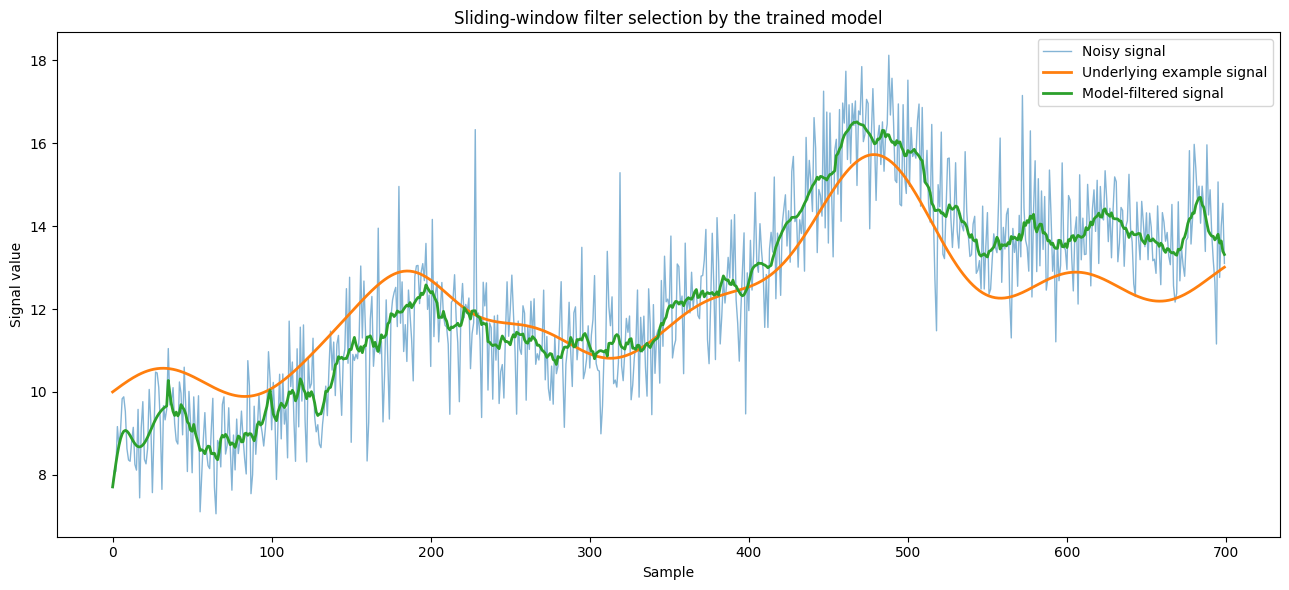

Filter chosen for each window:
Samples 0-99: Butterworth (cutoff=0.1, order=3)
Samples 35-134: Savitzky-Golay (window=9)
Samples 70-169: Moving Average (window=15)
Samples 105-204: Moving Average (window=15)
Samples 140-239: Moving Average (window=15)
Samples 175-274: Moving Average (window=15)
Samples 210-309: Moving Average (window=15)
Samples 245-344: Moving Average (window=15)
Samples 280-379: Moving Average (window=15)
Samples 315-414: Moving Average (window=15)
Samples 350-449: Moving Average (window=15)
Samples 385-484: Savitzky-Golay (window=15)
Samples 420-519: Moving Average (window=15)
Samples 455-554: Moving Average (window=15)
Samples 490-589: Moving Average (window=15)
Samples 525-624: Moving Average (window=15)
Samples 560-659: Moving Average (window=15)
Samples 595-694: Moving Average (window=15)
Samples 600-699: Moving Average (window=15)


In [30]:


# Load the model and use on any signal with same input features or define the features as per the model requirements

saved_model = joblib.load("Signal_processing_regressor.joblib")
model = saved_model ["model"]
feature_columns = saved_model["feature_columns"]

# These must match the window settings used when training.
WINDOW_SIZE = 100
STEP_SIZE = 35

# a demo signal to test the model again - real case simulation

rng = np.random.default_rng(10)  # Makes this example repeatable.
time = np.arange(700)

# A slowly changing baseline with broad peaks and a small oscillation.
clean_signal = (
    10
    + 0.004 * time
    + 2.5 * np.exp(-0.5 * ((time - 190) / 28) ** 2)
    + 3.5 * np.exp(-0.5 * ((time - 470) / 42) ** 2)
    + 0.45 * np.sin(2 * np.pi * time / 115)
)

# Add measurement noise plus a gradual sensor-baseline drift.
noise = rng.normal(0, 1, len(time))
drift = np.linspace(-1.2, 1.6, len(time))
noisy_signal = clean_signal + noise + drift

# Add a few occasional spikes, as can happen in sensor measurements.
spike_positions = rng.choice(len(time), size=8, replace=False)
noisy_signal[spike_positions] += rng.choice([-1, 1], size=8) * rng.uniform(2, 3.5, size=8)

#deine the same filter configuration used in training - as a tool to apply

FILTER_CONFIGS = []

for size in [5, 9, 15]:
    FILTER_CONFIGS.append({"filter_name": "Median", "filter_window": size,
                           "polyorder": np.nan, "cutoff": np.nan, "filter_order": np.nan})

for size in [5, 9, 15]:
    FILTER_CONFIGS.append({"filter_name": "Moving Average", "filter_window": size,
                           "polyorder": np.nan, "cutoff": np.nan, "filter_order": np.nan})

for size in [5, 9, 15]:
    FILTER_CONFIGS.append({"filter_name": "Savitzky-Golay", "filter_window": size,
                           "polyorder": 2, "cutoff": np.nan, "filter_order": np.nan})

for cutoff in [0.1, 0.2]:
    for order in [2, 3]:
        FILTER_CONFIGS.append({"filter_name": "Butterworth", "filter_window": np.nan,
                               "polyorder": np.nan, "cutoff": cutoff, "filter_order": order})

FILTER_CONFIGS.append({"filter_name": "Linear Detrending", "filter_window": np.nan,
                       "polyorder": np.nan, "cutoff": np.nan, "filter_order": np.nan})

#Applying the filter

def apply_filter(signal, config):

    name = config["filter_name"]

    if name == "Median":
        return median_filter(signal, size=int(config["filter_window"]))
    elif name == "Moving Average":
        return uniform_filter1d(signal, size=int(config["filter_window"]))
    elif name == "Savitzky-Golay":
        return savgol_filter(signal, window_length=int(config["filter_window"]),
                             polyorder=int(config["polyorder"]))
    elif name == "Butterworth":
        sos = butter(int(config["filter_order"]), config["cutoff"],
                     btype="low", output="sos")
        return sosfiltfilt(sos, signal)
    elif name == "Linear Detrending":
        return detrend(signal, type="linear") + np.mean(signal)

    raise ValueError("Unknown filter")


# Window sliding settings

starts = list(range(0, len(noisy_signal) - WINDOW_SIZE + 1, STEP_SIZE))
final_start = len(noisy_signal) - WINDOW_SIZE
if starts[-1] != final_start:
    starts.append(final_start)

# Overlapping windows are combined by averaging their filtered values.
filtered_total = np.zeros(len(noisy_signal))
coverage = np.zeros(len(noisy_signal))
selected_filters = []

for start in starts:
    end = start + WINDOW_SIZE
    noisy_window = noisy_signal[start:end]

    # These are the same signal features the model saw during training.
    window_features = {
        "window_mean": np.mean(noisy_window),
        "window_std": np.std(noisy_window),
        "window_range": np.ptp(noisy_window),
        "window_slope": np.polyfit(np.arange(WINDOW_SIZE), noisy_window, 1)[0],
        "window_roughness": np.std(np.diff(noisy_window)),
    }

    # Ask the model to predict a score for every available filter setup.
    candidates = []
    for config in FILTER_CONFIGS:
        row = {**window_features, **config}
        candidates.append(row)

    candidate_df = pd.DataFrame(candidates)
    candidate_df = candidate_df[feature_columns]
    predicted_SNR = model.predict(candidate_df)

    # Use the filter configuration with the highest predicted score.
    best_index = int(np.argmax(predicted_SNR))
    best_config = FILTER_CONFIGS[best_index]
    filtered_window = apply_filter(noisy_window, best_config)

    filtered_total[start:end] += filtered_window
    coverage[start:end] += 1
    selected_filters.append((start, best_config["filter_name"], best_config["filter_window"],
                             best_config["cutoff"], best_config["filter_order"]))

filtered_signal = filtered_total / coverage

#Visualization will show the original , signal with noise, and the filtered signal

plt.figure(figsize=(13, 6))
plt.plot(time, noisy_signal, label="Noisy signal", alpha=0.55, linewidth=1)
plt.plot(time, clean_signal, label="Underlying example signal", linewidth=2)
plt.plot(time, filtered_signal, label="Model-filtered signal", linewidth=2)
plt.xlabel("Sample")
plt.ylabel("Signal value")
plt.title("Sliding-window filter selection by the trained model")
plt.legend()
plt.tight_layout()
plt.show()

# Optional: show which filter family the model chose in each window.
print("Filter chosen for each window:")
for start, name, size, cutoff, order in selected_filters:
    settings = []
    if pd.notna(size):
        settings.append(f"window={int(size)}")
    if pd.notna(cutoff):
        settings.append(f"cutoff={cutoff}")
    if pd.notna(order):
        settings.append(f"order={int(order)}")
    extra = ", ".join(settings)
    print(f"Samples {start}-{start + WINDOW_SIZE - 1}: {name}" + (f" ({extra})" if extra else ""))


In [32]:
# Create one selected-filter entry for every sample.
selected_filter_column = [[] for _ in range(len(time))]

for start, name, size, cutoff, order in selected_filters:
    filter_label = f"{name}_{size}_{cutoff}_{order}"

    selected_filter_column[start:start + WINDOW_SIZE] = [
        values + [filter_label]
        for values in selected_filter_column[start:start + WINDOW_SIZE]
    ]

# Combine filter names where windows overlap.
selected_filter_column = [
    "; ".join(dict.fromkeys(filters))
    for filters in selected_filter_column
]

# Create one SNR entry for every sample.
sample_snr = [[] for _ in range(len(time))]

for start in starts:
    end = start + WINDOW_SIZE

    clean_window = clean_signal[start:end]
    filtered_window = filtered_signal[start:end]

    error_power = np.sum((clean_window - filtered_window) ** 2)
    signal_power = np.sum(clean_window ** 2)

    window_snr = 10 * np.log10(signal_power / error_power) if error_power > 0 else np.inf

    for sample in range(start, end):
        sample_snr[sample].append(window_snr)

# Average SNR values where windows overlap.
avg_snr = [
    np.mean(values) if values else np.nan
    for values in sample_snr
]

results_df = pd.DataFrame({
    "sample": time,
    "noise_type" : noise_type,
    "clean_signal": clean_signal,
    "noisy_signal": noisy_signal,
    "filtered_signal": filtered_signal,
    "selected_filter": selected_filter_column,
    "SNR": avg_snr
})

results_df.to_csv("regressor_results_new.csv", index=False)

In [48]:
print(f"Average SNR of the signal:\n{results_df['SNR'].mean():.2f}")

print("\nHighest SNR:")
print(results_df.loc[results_df["SNR"].idxmax(), ["SNR", "noise_type", "selected_filter"]])

print("\nLowest SNR:")
print(results_df.loc[results_df["SNR"].idxmin(), ["SNR", "noise_type", "selected_filter"]])

#also checking the noise_type and the filter performed worst
print("\nLowest 10 SNR values:")

print(results_df.nsmallest(10, "SNR")[["SNR","noise_type", "selected_filter"]])

print("\nHighest 10 SNR values:")
print(results_df.nlargest(10, "SNR") [["SNR", "noise_type", "selected_filter"]])

Average SNR of the signal:
23.99

Highest SNR:
SNR                                32.481914
noise_type                             drift
selected_filter    Moving Average_15_nan_nan
Name: 345, dtype: object

Lowest SNR:
SNR                            18.142015
noise_type                         drift
selected_filter    Butterworth_nan_0.1_3
Name: 0, dtype: object

Lowest 10 SNR values:
         SNR noise_type        selected_filter
0  18.142015      drift  Butterworth_nan_0.1_3
1  18.142015      drift  Butterworth_nan_0.1_3
2  18.142015      drift  Butterworth_nan_0.1_3
3  18.142015      drift  Butterworth_nan_0.1_3
4  18.142015      drift  Butterworth_nan_0.1_3
5  18.142015      drift  Butterworth_nan_0.1_3
6  18.142015      drift  Butterworth_nan_0.1_3
7  18.142015      drift  Butterworth_nan_0.1_3
8  18.142015      drift  Butterworth_nan_0.1_3
9  18.142015      drift  Butterworth_nan_0.1_3

Highest 10 SNR values:
           SNR noise_type            selected_filter
345  32.481914   